## **UTS PREDIKSI MODERN & MACHINE LEARNING**
#### Nama  : Nadine Lenora
#### NIM   : 2404220024
#### Prodi : Statistika dan Sains Data

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
from IPython.display import display
from sklearn.pipeline import Pipeline

def evaluate_model(model, X_train, y_train, X_test, y_test):
    # 5-fold CV F1-score
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1')
    cv_f1 = cv_scores.mean()

    fold_df = pd.DataFrame({
        'Fold': ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5'],
        'F1-score': np.round(cv_scores, 4)
    })
    print("Hasil CV F1-score per Fold:")
    display(fold_df)
    print("-" * 30)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"CV F1-score (5-fold): {cv_f1:.4f}")
    print(f"Test Accuracy       : {acc:.4f}")
    print(f"Test Precision      : {prec:.4f}")
    print(f"Test Recall         : {rec:.4f}")
    print(f"Test F1-score       : {f1:.4f}")

    return cv_f1, acc, prec, rec, f1

### EKSPERIMEN 0: DATA UNDERSTANDING DAN PREPARATION

In [35]:
# Dataset
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")
files = os.listdir(path)
csv_filename = [f for f in files if f.endswith('.csv')][0]
file_path = os.path.join(path, csv_filename)

df = pd.read_csv(file_path)

# Dimensi dan struktur data
print("Dimensi Dataset:", df.shape)
df.info()

# Gambaran awal data
display(df.head())

# Missing values dan duplikat
print("\nMissing Values:\n", df.isnull().sum().sum())
print("Duplikat:", df.duplicated().sum())
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print("Duplikat berhasil dihapus.")

display(df.describe().T)

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.
Dimensi Dataset: (30000, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                  

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0



Missing Values:
 0
Duplikat: 0


,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


**INTERPRETASI**

Berdasarkan hasil dari data understanding dan preparation, didapat bahwa dataset yang digunakan berdimensi 30.000 baris dan 25 kolom, di mana semua kolom numerik tidak terdapat missing value ataupun data duplikat. Sehingga tidak diperlukan imputasi atau penghapusan baris.

In [26]:
# Pengecekan nilai kategorik
print("SEX        :", sorted(df['SEX'].unique()))
print("EDUCATION  :", sorted(df['EDUCATION'].unique()))
print("MARRIAGE   :", sorted(df['MARRIAGE'].unique()))

print("\n", df["SEX"].value_counts(), "\n")
print(df["EDUCATION"].value_counts(), "\n")
print(df["MARRIAGE"].value_counts(), "\n")

# Pengecekan kolom PAY
pay_cols = ['PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
for c in pay_cols:
    print(c, sorted(df[c].unique()))

print("\nDistribusi PAY_0:")
print(df["PAY_0"].value_counts().sort_index())

# Pengecekan nilai numerik yang mencurigakan
bill_cols = [f'BILL_AMT{i}' for i in range(1,7)]
amt_cols  = [f'PAY_AMT{i}'  for i in range(1,7)]

print("\nJumlah BILL_AMT negatif per kolom:")
print((df[bill_cols] < 0).sum())

print("\nJumlah PAY_AMT negatif:", (df[amt_cols] < 0).sum().sum())
print("LIMIT_BAL <= 0        :", (df['LIMIT_BAL'] <= 0).sum())
print("Rentang AGE           :", df['AGE'].min(), "-", df['AGE'].max())

# Perapihan kategori (setelah pengecekan)
df['MARRIAGE'] = df['MARRIAGE'].replace(0, 3)
df['EDUCATION'] = df['EDUCATION'].replace([0, 5, 6], 4)

print("\nSetelah perapihan:")
print(df["EDUCATION"].value_counts(), "\n")
print(df["MARRIAGE"].value_counts(), "\n")

SEX        : [np.int64(1), np.int64(2)]
EDUCATION  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE   : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

 SEX
2    18112
1    11888
Name: count, dtype: int64 

EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64 

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64 

PAY_0 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int6

**INTERPRETASI**

Untuk kolom Education, terlihat bahwa terdapat kode yang tidak terdefinisi, yaitu 0 (14 baris), 5 (280 baris), dan 6 (51 baris). Kemudian ketiga kode tersebut digabung ke kategori 4 (others), sehingga kategori 4 menjadi 468 baris. Penggabungan kode ini dipilih supaya informasi yang ada tidak hilang. Begitu pula untuk kolom Marriage, di mana terdapat kode yang tidak terdefinisi, yaitu 0 (54 baris), sehingga kode tersebut digabung ke kategori 3 (others) menjadi 377 baris.

Untuk kolom PAY_0 - PAY 6 juga terdapat nilai yang tidak terdefinisi, yaitu nilai -2 dan 0. Pada PAY_0, nilai -2 berjumlah 2759, -1 berjumlah 5.686, dan 0 berjumlah 14.737. Dikarenakan jumlahnya yang besar dan membawa informasi status pembayaran, maka nilai ini dipertahankan. Selain itu kolom PAY_* merupakan variabel numerik ordinal karena semakin besar nilainya, sebakin buruk status pembayarannya.

Pada kolom BILL_AMT1 - 6 terdapat nilai negatif sekitar 590-688 baris per kolom, dengan nilai minimum hingga -339.603. Hal ini dipertahankan karena masih wajar secara bisnis, misalnya nasabah membayar melebihi tagihan sehingga saldo menjadi kredit.

Untuk variabel lainnya seperti PAY_AMT tidak memiliki nilai negatif, LIMIT_BAL menujukkan nilai minimum 10.000, dan variabel AGE berada pada rentang 21-79 tahun.


Distribusi Target:
 default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64
Jumlah data per kelas:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64


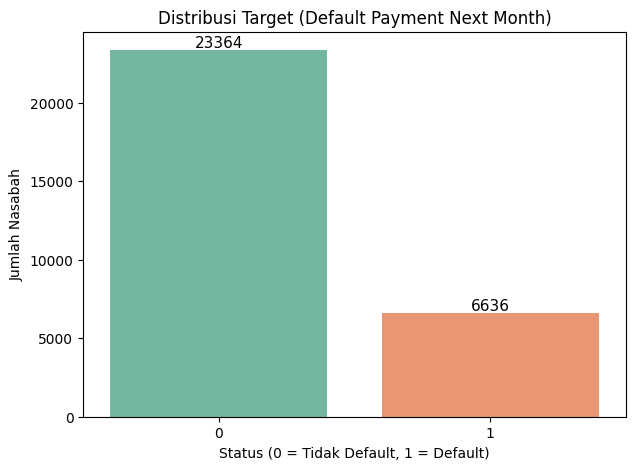


Dimensi X_train: (24000, 23)
Dimensi X_test: (6000, 23)


In [36]:
# Target dan prediktor
target_col = 'default.payment.next.month'
print("\nDistribusi Target:\n", df[target_col].value_counts(normalize=True))

print("Jumlah data per kelas:")
print(df[target_col].value_counts())

# Visualisasi
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target_col, palette='Set2')
plt.title('Distribusi Target (Default Payment Next Month)')
plt.xlabel('Status (0 = Tidak Default, 1 = Default)')
plt.ylabel('Jumlah Nasabah')
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.show()

# Mengeluarkan variabel ID dari prediktor
X = df.drop(columns=['ID', target_col])
y = df[target_col]

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("\nDimensi X_train:", X_train.shape)
print("Dimensi X_test:", X_test.shape)

**INTERPRETASI**

Berdasarkan visualisasi bar chart dapat dilihat bahwa kelas 0 (tidak mengalami default) sebanyak 23.364 (77.88%) dan kelas 1 (mengalami default) sebanyak 6.636 (22.12%), di mana data tidak seimbang. Sehingga accuracy kurang tepat sebagai metrik utama, maka F1-score digunakan sebagai metrik utama.

Split data dilakukan dengan rasio 80:20, menghasilkan 24.000 data latih dan 6000 data uji. Scaling pada eksperimen selanjutnya dilakukan di dalam Pipeline agar hanya dipelajari dari data latih per fold. Sedangkan untuk resampling tidak digunakan, karena imbalance class ditangani lewat class_wight dan scale_pos_weight pada eksperimen berikutnya.

### EKSPERIMEN 1: MODEL BASELINE (REGRESI LOGISTIK)

In [28]:
warnings.resetwarnings()

print("--- EXPERIMENT 1: BASELINE MODEL (LOGISTIC REGRESSION) ---")
baseline_model = LogisticRegression(random_state=42, max_iter=5000)

print("\nHasil Evaluasi Baseline:")
res_exp1 = evaluate_model(baseline_model, X_train, y_train, X_test, y_test)

warnings.filterwarnings('ignore')

--- EXPERIMENT 1: BASELINE MODEL (LOGISTIC REGRESSION) ---

Hasil Evaluasi Baseline:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs 

Hasil CV F1-score per Fold:


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Fold,F1-score
0,Fold 1,0.3561
1,Fold 2,0.3665
2,Fold 3,0.3732
3,Fold 4,0.3620
4,Fold 5,0.3555


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(


------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CV F1-score (5-fold): 0.3627
Test Accuracy       : 0.8080
Test Precision      : 0.6874
Test Recall         : 0.2419
Test F1-score       : 0.3579


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**INTERPRETASI**

Berdasarkan model Baseline, didapat nilai CV F! sebesar 0.3627 dan Test F! sebesar 0.3579 dengan akurasi sebesar 0.8080 dan precision sebesar 0.6874, namun recall pada model ini hanya sebesar 0.2419. Artinya model hanya menangkap sekitar 24% nasabah yang benar-benar default. Akurasi yang tinggi pada model ini menunjukkan bahwa model cenderung memprediksi "tidak default" dikarenakan data kelas 0 yang mendominasi.

Selain itu, pada model baseline juga muncul ConvergenceWarning, yang mengindikasikan bahwa model belum kovergen meskipun max_iter=5000. Hal ini disebabkan perbedaan skala antarfitur yang besar karena data belum dilakukan feature scaling, maka dari itu masalah konvergensi ini menjadi salah satu alasan dilakukannya scaling pada Eksperimen 2.

### EKSPERIMEN 2: BASELINE MODEL + PREPROCESSING

In [29]:
prep_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=42, max_iter=1000))
])

print("\nHasil Evaluasi Baseline + Preprocessing (Pipeline):")
res_exp2 = evaluate_model(prep_pipeline, X_train, y_train, X_test, y_test)

cols = ["CV F1","Test Accuracy","Test Precision","Test Recall","Test F1"]
cmp12 = pd.DataFrame([res_exp1, res_exp2], index=["Exp 1 (Baseline)","Exp 2 (+Scaling)"], columns=cols)
cmp12.loc["Selisih"] = cmp12.loc["Exp 2 (+Scaling)"] - cmp12.loc["Exp 1 (Baseline)"]
display(cmp12.round(4))


Hasil Evaluasi Baseline + Preprocessing (Pipeline):
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.3578
1,Fold 2,0.3783
2,Fold 3,0.3754
3,Fold 4,0.3628
4,Fold 5,0.3566


------------------------------
CV F1-score (5-fold): 0.3662
Test Accuracy       : 0.8083
Test Precision      : 0.6903
Test Recall         : 0.2419
Test F1-score       : 0.3583


,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Exp 1 (Baseline),0.3627,0.8080,0.6874,0.2419,0.3579
Exp 2 (+Scaling),0.3662,0.8083,0.6903,0.2419,0.3583
Selisih,0.0035,0.0003,0.0030,0.0000,0.0004


**INTERPRETASI**

Setelah dlakukan scaling, terlihat bahwa warning konvergensi tidak muncul kembali yang mengindikasikan optimasi berjalan dengan stabil. Namun metrik recall tetap 0,2419, yang menunjukkan bahwa keterbatasan baseline dikarenakan ketidakseimbangan kelas, bukan karena masalah konvergensi.

Preprocessing yang dilakukan meningkatkan performa walaupun sangat kecil. Terlihat bahwa recall tidak berubah dan kenaikan F!-score hanya sebesar 0.0004. StandarScaler digunakan untuk membantu agar konvergensi berjalan dengan optimal, bukan untuk meningkatkan kemampuan prediksi. Selain itu Encoding tidak diterapkan karena variabel SEX, EDUCATION, dan MARRIAGE sudah berbentuk kode numerik.

### EKSPERIMEN 3: MODEL COMPARISON

In [30]:
print("--- EXPERIMENT 3: MODEL COMPARISON ---")

models = {
    "Logistic Regression (Scaled)": Pipeline([
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    print(f"\nModel: {name}")
    results[name] = evaluate_model(model, X_train, y_train, X_test, y_test)

    import pandas as pd
from IPython.display import display

# Tabel perbandingan
print("--- TABEL PERBANDINGAN MODEL (EKSPERIMEN 3) ---")

data_exp3 = {
    "Model": list(results.keys()),
    "CV F1-score": [res[0] for res in results.values()],
    "Test Accuracy": [res[1] for res in results.values()],
    "Test Precision": [res[2] for res in results.values()],
    "Test Recall": [res[3] for res in results.values()],
    "Test F1-score": [res[4] for res in results.values()]
}

df_exp3 = pd.DataFrame(data_exp3)
display(df_exp3)

--- EXPERIMENT 3: MODEL COMPARISON ---

Model: Logistic Regression (Scaled)
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.3578
1,Fold 2,0.3783
2,Fold 3,0.3754
3,Fold 4,0.3628
4,Fold 5,0.3566


------------------------------
CV F1-score (5-fold): 0.3662
Test Accuracy       : 0.8083
Test Precision      : 0.6903
Test Recall         : 0.2419
Test F1-score       : 0.3583

Model: Decision Tree
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.3937
1,Fold 2,0.4030
2,Fold 3,0.4221
3,Fold 4,0.3843
4,Fold 5,0.3897


------------------------------
CV F1-score (5-fold): 0.3985
Test Accuracy       : 0.7195
Test Precision      : 0.3766
Test Recall         : 0.4092
Test F1-score       : 0.3922

Model: Random Forest
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.4723
1,Fold 2,0.4639
2,Fold 3,0.4640
3,Fold 4,0.4808
4,Fold 5,0.4564


------------------------------
CV F1-score (5-fold): 0.4675
Test Accuracy       : 0.8142
Test Precision      : 0.6429
Test Recall         : 0.3595
Test F1-score       : 0.4611
--- TABEL PERBANDINGAN MODEL (EKSPERIMEN 3) ---


,Model,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Logistic Regression (Scaled),0.366158,0.808333,0.690323,0.241899,0.358259
1,Decision Tree,0.398528,0.719500,0.376560,0.409194,0.392199
2,Random Forest,0.467471,0.814167,0.642857,0.359457,0.461092


**INTERPRETASI**

Berdasarkan hasil perbandingan dari ketiga model, dapat dilihat bahwa Random Forest memberikan hasil yang paling baik, di mana CV F1 0.4675 dan Test F1 0.4611, dengan accracy tertinggi (0.8142). Model Decision Tree memiliki nilai recall yang paling tinggi (0.4092), namun nilai akurasi (0.7195) dan nilai precisionnya (0.3766) merupakan yang terendah dibanding dengan model lainnya. Hal ini mengindikasikan adanya overfitting pohon tunggal.

Sedangkan model Logistic Regression memiliki precision tertinggi (0.6903) tetapi dengan recall terendah (0.2419), karena model linear kurang mampu menangkap pola non-linear. Dikarenakan selisih antara CV F1 dan Test F1 pada Random Forest kecil, maka dapat disimpulkan bahwa performanya stabil. Sehingga model Random Forest dipilih sebagai model terbaik berdasarkan F1-score dan akan digunakan pada Eksperimen 4.

### EKSPERIMEN 4: HYPERPARAMETER TUNING

In [31]:
# Sebelum tuning
rf_base = RandomForestClassifier(random_state=42)
print("Evaluasi Model SEBELUM Tuning (Default Random Forest):")
res_exp4_before = evaluate_model(rf_base, X_train, y_train, X_test, y_test)

# Hyperparameter tuning
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'class_weight': [None, 'balanced']
}
grid_search = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Hyperparameter yang diuji:", param_grid)
print(f"Best CV F1-score: {grid_search.best_score_:.4f}")

best_tuned_model = grid_search.best_estimator_
print("\nKombinasi hyperparameter terbaik:")
print(grid_search.best_params_)

# Setelah tuning
print("\nEvaluasi Model setelah Tuning (Best Estimator):")
res_exp4_after = evaluate_model(best_tuned_model, X_train, y_train, X_test, y_test)

# Tabel perbandingan
print("\n--- TABEL PERBANDINGAN SEBELUM VS SESUDAH TUNING ---")

comparison_data = {
    "Kondisi Model": ["Sebelum Tuning (Default)", "Sesudah Tuning (Tuned)"],
    "CV F1-score": [res_exp4_before[0], res_exp4_after[0]],
    "Test Accuracy": [res_exp4_before[1], res_exp4_after[1]],
    "Test Precision": [res_exp4_before[2], res_exp4_after[2]],
    "Test Recall": [res_exp4_before[3], res_exp4_after[3]],
    "Test F1-score": [res_exp4_before[4], res_exp4_after[4]]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

Evaluasi Model SEBELUM Tuning (Default Random Forest):
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.4723
1,Fold 2,0.4639
2,Fold 3,0.4640
3,Fold 4,0.4808
4,Fold 5,0.4564


------------------------------
CV F1-score (5-fold): 0.4675
Test Accuracy       : 0.8142
Test Precision      : 0.6429
Test Recall         : 0.3595
Test F1-score       : 0.4611
Hyperparameter yang diuji: {'n_estimators': [50, 100], 'max_depth': [10, 20, None], 'min_samples_split': [2, 5], 'class_weight': [None, 'balanced']}
Best CV F1-score: 0.5450

Kombinasi hyperparameter terbaik:
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}

Evaluasi Model setelah Tuning (Best Estimator):
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.5525
1,Fold 2,0.5491
2,Fold 3,0.5367
3,Fold 4,0.5464
4,Fold 5,0.5404


------------------------------
CV F1-score (5-fold): 0.5450
Test Accuracy       : 0.7880
Test Precision      : 0.5191
Test Recall         : 0.5622
Test F1-score       : 0.5398

--- TABEL PERBANDINGAN SEBELUM VS SESUDAH TUNING ---


,Kondisi Model,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Sebelum Tuning (Default),0.467471,0.814167,0.642857,0.359457,0.461092
1,Sesudah Tuning (Tuned),0.544994,0.788000,0.519137,0.562170,0.539797


**INTERPRETASI**

Kombinasi parameter terbaik adalah class_wight='balance', max_depth=10, min_samples_split=5, n_estimators=100.
Berdasarkan hasil tabel perbandingan dapat dilihat bahwa tuning meningkatkan F1 (CV +0.0775 dan test +0.0787), selain itu recall juga meningkat dari 0.3595 mejadi 0.5622. Namun dengan meningkatnya recall dan F1, precision dan accuracy menurun. Hal ini dikarenakan class_wight=balanced membuat model lebih sensitif terhadap nasabah default, dan max_depth=10 mengurangi overfitting.

### EKSPERIMEN 5: ADVANCED MODEL

In [32]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

advanced_models = {
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=ratio),
    "LightGBM": LGBMClassifier(random_state=42, scale_pos_weight=ratio, verbose=-1)
}

res_exp5_models = {}

for name, model in advanced_models.items():
    print(f"\nEvaluasi Model: {name}")
    res_exp5_models[name] = evaluate_model(model, X_train, y_train, X_test, y_test)


Evaluasi Model: XGBoost
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.5127
1,Fold 2,0.5265
2,Fold 3,0.5045
3,Fold 4,0.5152
4,Fold 5,0.5214


------------------------------
CV F1-score (5-fold): 0.5161
Test Accuracy       : 0.7627
Test Precision      : 0.4701
Test Recall         : 0.5750
Test F1-score       : 0.5173

Evaluasi Model: LightGBM
Hasil CV F1-score per Fold:


,Fold,F1-score
0,Fold 1,0.5366
1,Fold 2,0.5501
2,Fold 3,0.5249
3,Fold 4,0.5387
4,Fold 5,0.5392


------------------------------
CV F1-score (5-fold): 0.5379
Test Accuracy       : 0.7560
Test Precision      : 0.4619
Test Recall         : 0.6262
Test F1-score       : 0.5317


In [33]:
print("--- PERBANDINGAN XGBOOST VS LIGHTGBM (EKSPERIMEN 5) ---")
data_exp5 = {
    "Model Advanced": ["XGBoost", "LightGBM"],
    "CV F1-score": [res_exp5_models["XGBoost"][0], res_exp5_models["LightGBM"][0]],
    "Test Accuracy": [res_exp5_models["XGBoost"][1], res_exp5_models["LightGBM"][1]],
    "Test Precision": [res_exp5_models["XGBoost"][2], res_exp5_models["LightGBM"][2]],
    "Test Recall": [res_exp5_models["XGBoost"][3], res_exp5_models["LightGBM"][3]],
    "Test F1-score": [res_exp5_models["XGBoost"][4], res_exp5_models["LightGBM"][4]]
}
df_exp5 = pd.DataFrame(data_exp5)
display(df_exp5)

# Perbandingan model terbaik
print("\n--- PERBANDINGAN MODEL TERBAIK (EXP 4 VS EXP 5) ---")
data_final = {
    "Tahap Eksperimen": ["Eksperimen 4 (Tuned Random Forest)", "Eksperimen 5 (LightGBM)"],
    "CV F1-score": [res_exp4_after[0], res_exp5_models["LightGBM"][0]],
    "Test Accuracy": [res_exp4_after[1], res_exp5_models["LightGBM"][1]],
    "Test Precision": [res_exp4_after[2], res_exp5_models["LightGBM"][2]],
    "Test Recall": [res_exp4_after[3], res_exp5_models["LightGBM"][3]],
    "Test F1-score": [res_exp4_after[4], res_exp5_models["LightGBM"][4]]
}
df_final = pd.DataFrame(data_final)
display(df_final)

--- PERBANDINGAN XGBOOST VS LIGHTGBM (EKSPERIMEN 5) ---


,Model Advanced,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,XGBoost,0.516092,0.762667,0.470117,0.574981,0.517288
1,LightGBM,0.537877,0.756000,0.461923,0.626225,0.531670



--- PERBANDINGAN MODEL TERBAIK (EXP 4 VS EXP 5) ---


,Tahap Eksperimen,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score
0,Eksperimen 4 (Tuned Random Forest),0.544994,0.788,0.519137,0.562170,0.539797
1,Eksperimen 5 (LightGBM),0.537877,0.756,0.461923,0.626225,0.531670


**INTERPRETASI**

Advance model yang digunakan pada eksperimen ini adalah XGBoost dan LightGBM. Berdasarkan hasil eksperimen, didapat bahwa model LightGBM dengan CV F1 0.5379 dan Test F1 0.5317 lebih baik daripada XGBoost dengan CV F1 0.5161 dan Test F1 0.5173.

Walaupun model LightGBM lebih baik dibandingkan dengan model XGBoost, namun tidak melampaui model Random Forest tuned dengan CV F1 0.5450 dan Test F1 0.5398. Model Random Forest tuned unggul di CV F1, test F1, accuracy, dan precision, sedangkan LightGBM hanya unggul pada metrik recall (0.6262). Model boosting dijalankan dengan hyperparameter default, hanya scale_pos_weight yang diatur, sehingga kemampuan model kemungkinan masih bisa meningkat bila di-tuning. Berdasarkan eksperimen ini, maka dapat diambil kesimpulan bahwa model yang lebih kompleks tidak selalu menghasilkan performa lebih baik.

In [34]:
summary = pd.DataFrame([
    ["1", "Logistic Regression (Baseline)", *res_exp1],
    ["2", "LR + StandardScaler", *res_exp2],
    ["3", "Random Forest (terbaik Exp 3)", *results["Random Forest"]],
    ["4", "Random Forest (Tuned)", *res_exp4_after],
    ["5", "LightGBM", *res_exp5_models["LightGBM"]],
], columns=["Experiment","Model","CV F1","Test Accuracy","Test Precision","Test Recall","Test F1"]).round(4)
display(summary)

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Logistic Regression (Baseline),0.3627,0.8080,0.6874,0.2419,0.3579
1,2,LR + StandardScaler,0.3662,0.8083,0.6903,0.2419,0.3583
2,3,Random Forest (terbaik Exp 3),0.4675,0.8142,0.6429,0.3595,0.4611
3,4,Random Forest (Tuned),0.5450,0.7880,0.5191,0.5622,0.5398
4,5,LightGBM,0.5379,0.7560,0.4619,0.6262,0.5317
